# **King County - Housing Price Prediction Models**
This notebook works by first evaluating a few simpler algorithms as a baseline, prior to implementing a GNN for modeling real-estate price flucutations. 

Pipeline overview:
- Load `kc_cleaned_data.csv`, split **80 / 10 / 10** (train / validation / test) on the input features, and predict **`log_price`**.
- Algorithms used: LinearRegression, XGBoost, CatBoost & Graph Neural Networks (GNNs)

In [1]:
from pathlib import Path

import pandas as pd
from catboost import CatBoostRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor

df = pd.read_csv("/Users/advaychandramouli/dev/projects/KingSight/data/kc_cleaned_data.csv")
df.head()

,id,date,zipcode,price,log_price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,...,waterfront,view,condition,grade,yr_built,yr_renovated,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,98178,221900.0,12.309982,-0.398737,-1.447464,-0.979835,-0.228321,-0.808531,...,-0.087173,-0.305759,-0.629187,-0.558836,-0.544898,-0.210128,-0.352572,-0.306079,-0.943355,-0.260715
1,6414100192,20141209T000000,98125,538000.0,13.195614,-0.398737,0.175607,0.533634,-0.189885,1.003454,...,-0.087173,-0.305759,-0.629187,-0.558836,-0.681079,4.746678,1.161568,-0.746341,-0.432686,-0.187868
2,5631500400,20150225T000000,98028,180000.0,12.100712,-1.473959,-1.447464,-1.426254,-0.123298,-0.808531,...,-0.087173,-0.305759,-0.629187,-1.409587,-1.293892,-0.210128,1.283537,-0.135655,1.070140,-0.172375
3,2487200875,20141209T000000,98136,604000.0,13.311329,0.676485,1.149449,-0.130550,-0.244014,-0.808531,...,-0.087173,-0.305759,2.444294,-0.558836,-0.204446,-0.210128,-0.283288,-1.271816,-0.914174,-0.284522
4,1954400510,20150218T000000,98074,510000.0,13.142166,-0.398737,-0.149007,-0.435422,-0.169653,-0.808531,...,-0.087173,-0.305759,-0.629187,0.291916,0.544548,-0.210128,0.409550,1.199335,-0.272190,-0.192849


## Feature Selection

Drop identifiers (`id`, `date`) and the raw sale `price` so the models cannot leak the target. `log_price` is the regression target.

In [2]:
RANDOM_STATE = 42
TARGET = "log_price"
DROP_COLS = ["id", "date", "price", TARGET]

X = df.drop(columns=DROP_COLS)
y = df[TARGET]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE
)

print(f"train: {len(X_train):,} ({len(X_train) / len(df):.0%})")
print(f"val:   {len(X_val):,} ({len(X_val) / len(df):.0%})")
print(f"test:  {len(X_test):,} ({len(X_test) / len(df):.0%})")
print(f"features ({X.shape[1]}): {list(X.columns)}")

train: 17,290 (80%)
val:   2,161 (10%)
test:  2,162 (10%)
features (18): ['zipcode', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'sqft_above', 'sqft_basement', 'waterfront', 'view', 'condition', 'grade', 'yr_built', 'yr_renovated', 'lat', 'long', 'sqft_living15', 'sqft_lot15']


## Baseline Models

### Linear Regression

In [3]:
# Initialize and load LinReg model 
linreg_model = LinearRegression()

# Fit on training data
linreg_model.fit(X_train, y_train)
y_pred = linreg_model.predict(X_test)

In [4]:
# Performance Evaluations
print("Coefficients:", linreg_model.coef_)
print("Intercept:", linreg_model.intercept_)
print("R2 Score:", r2_score(y_test, y_pred))
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))

Coefficients: [-0.00060484 -0.00960438  0.05937772  0.0666823   0.0165158   0.03480958
  0.05666221  0.03236126  0.03245641  0.04763472  0.03933431  0.1850765
 -0.10597614  0.01405493  0.19471074 -0.01948828  0.06531136 -0.00509555]
Intercept: 72.36847447216685
R2 Score: 0.7847807958117395
Mean Absolute Error: 0.19558380139110967
Mean Squared Error: 0.06411731546114317


### XGBoost

In [5]:
xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    early_stopping_rounds=50,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

xgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
y_pred = xgb_model.predict(X_test)

In [6]:
# Performance Evaluations
print("Best iteration:", xgb_model.best_iteration)
print("R2 Score:", r2_score(y_test, y_pred))
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))

Best iteration: 390
R2 Score: 0.917418356391456
Mean Absolute Error: 0.11312447078727896
Mean Squared Error: 0.024602420190704986


### CatBoost

In [7]:
cat_model = CatBoostRegressor(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    loss_function="RMSE",
    early_stopping_rounds=50,
    random_seed=RANDOM_STATE,
    verbose=False,
)

cat_model.fit(X_train, y_train, eval_set=(X_val, y_val))
y_pred = cat_model.predict(X_test)

In [8]:
# Performance Evaluations
print("Best iteration:", cat_model.get_best_iteration())
print("R2 Score:", r2_score(y_test, y_pred))
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))

Best iteration: 499
R2 Score: 0.9133905251546046
Mean Absolute Error: 0.1170573850534945
Mean Squared Error: 0.02580237689071927


## XGBoost + Neighborhood Summaries

Augment the strongest baseline with **k-nearest-neighbor summaries** built from geography only:

- Fit `NearestNeighbors` (haversine on raw `lat`/`long` from `kc_house_data.csv`, since the cleaned CSV is z-scored) on the **training split only**.
- For each house, average its **15 nearest neighbors'** `grade`, `sqft_living`, and **building age** (`sale_year - yr_built`) — mirroring the `sqft_living15` convention.
- Sale prices are **excluded** from the summaries, so there is no target leakage. Train rows exclude themselves; validation/test rows draw neighbors from the training pool only (no transductive leakage).

This tests whether simple neighborhood structure helps before moving to a full GNN.

In [9]:
import numpy as np
from sklearn.neighbors import NearestNeighbors

K_NEIGHBORS = 15  # matches the sqft_living15 convention

# Raw lat/long and yr_built (the cleaned CSV is z-scored), joined on id.
# The raw file contains a few duplicate ids that preprocessing dropped.
raw = pd.read_csv(
    "/Users/advaychandramouli/dev/projects/KingSight/data/kc_house_data.csv",
    usecols=["id", "lat", "long", "yr_built"],
).set_index("id")
raw = raw[~raw.index.duplicated(keep="first")]

sale_year = pd.to_datetime(df["date"]).dt.year
geo = raw.loc[df["id"]].reset_index(drop=True)
assert len(geo) == len(df), "id join must stay row-aligned with the cleaned data"
geo["building_age"] = sale_year - geo["yr_built"]

# Neighbor source values: z-scored grade / sqft_living from the cleaned data,
# building age in years. No price or log_price anywhere -> no target leakage.
nbr_values = np.column_stack(
    [df["grade"], df["sqft_living"], geo["building_age"]]
)
NBR_FEATURE_NAMES = ["nbr_avg_grade", "nbr_avg_sqft_living", "nbr_avg_building_age"]

train_idx = X_train.index.to_numpy()
coords_rad = np.radians(geo[["lat", "long"]].to_numpy())

nn_model = NearestNeighbors(n_neighbors=K_NEIGHBORS + 1, metric="haversine")
nn_model.fit(coords_rad[train_idx])


def neighbor_means(query_idx: np.ndarray) -> pd.DataFrame:
    """Mean of each query row's K nearest TRAIN neighbors (self excluded)."""
    _, nbrs = nn_model.kneighbors(coords_rad[query_idx])
    means = np.empty((len(query_idx), len(NBR_FEATURE_NAMES)))
    for row, (q_idx, row_nbrs) in enumerate(zip(query_idx, nbrs)):
        keep = [n for n in row_nbrs if train_idx[n] != q_idx][:K_NEIGHBORS]
        means[row] = nbr_values[train_idx[keep]].mean(axis=0)
    return pd.DataFrame(means, columns=NBR_FEATURE_NAMES, index=query_idx)

In [10]:
X_train_nbr = X_train.join(neighbor_means(X_train.index.to_numpy()))
X_val_nbr = X_val.join(neighbor_means(X_val.index.to_numpy()))
X_test_nbr = X_test.join(neighbor_means(X_test.index.to_numpy()))

print(f"features ({X_train_nbr.shape[1]}): {list(X_train_nbr.columns)}")
X_train_nbr[NBR_FEATURE_NAMES].describe()

# Same hyperparameters as the baseline XGBoost for a clean comparison.
xgb_nbr_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    early_stopping_rounds=50,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

xgb_nbr_model.fit(X_train_nbr, y_train, eval_set=[(X_val_nbr, y_val)], verbose=False)
y_pred_nbr = xgb_nbr_model.predict(X_test_nbr)

features (21): ['zipcode', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'sqft_above', 'sqft_basement', 'waterfront', 'view', 'condition', 'grade', 'yr_built', 'yr_renovated', 'lat', 'long', 'sqft_living15', 'sqft_lot15', 'nbr_avg_grade', 'nbr_avg_sqft_living', 'nbr_avg_building_age']


In [11]:
# Performance comparison: baseline XGBoost vs. XGBoost + neighborhood summaries
y_pred_base = xgb_model.predict(X_test)

comparison = pd.DataFrame(
    {
        "XGBoost (baseline)": {
            "R2": r2_score(y_test, y_pred_base),
            "MAE": mean_absolute_error(y_test, y_pred_base),
            "MSE": mean_squared_error(y_test, y_pred_base),
        },
        "XGBoost + neighborhood": {
            "R2": r2_score(y_test, y_pred_nbr),
            "MAE": mean_absolute_error(y_test, y_pred_nbr),
            "MSE": mean_squared_error(y_test, y_pred_nbr),
        },
    }
).T

print("Best iteration (neighborhood model):", xgb_nbr_model.best_iteration)
print(comparison)
print(
    "dR2: {:+.4f}".format(
        comparison.loc["XGBoost + neighborhood", "R2"]
        - comparison.loc["XGBoost (baseline)", "R2"]
    )
)

Best iteration (neighborhood model): 361
                              R2       MAE       MSE
XGBoost (baseline)      0.917418  0.113124  0.024602
XGBoost + neighborhood  0.917721  0.112761  0.024512
dR2: +0.0003


**Takeaway:** the neighborhood summaries add almost nothing (test R² 0.9174 → 0.9177, Δ ≈ +0.0003). This is expected given the SHAP analysis below: `lat`/`long` plus the existing `sqft_living15` already encode most of the *smooth* neighborhood signal, and averaging 15 neighbors' grade/size/age is just a smoothed copy of features the trees already split on. Simple neighborhood aggregation is therefore not where the gains are — a GNN would need to exploit *non-smooth* graph structure (e.g. house-specific edge weights, heterogeneous neighbor influence) to beat the tabular baseline.

## Explainability (LIME & SHAP)

Take the best baseline by test **R²** (expected: XGBoost) and explain it globally with SHAP and locally with LIME. Features are already z-scored in `kc_cleaned_data.csv`, so attributions are in standardized units.

In [12]:
import matplotlib.pyplot as plt
import shap
from lime.lime_tabular import LimeTabularExplainer

candidates = {
    "LinearRegression": linreg_model,
    "XGBoost": xgb_model,
    "CatBoost": cat_model,
}
scores = {
    name: r2_score(y_test, model.predict(X_test))
    for name, model in candidates.items()
}
best_name = max(scores, key=scores.get)
best_model = candidates[best_name]

print("Test R2 by model:")
for name, score in sorted(scores.items(), key=lambda item: item[1], reverse=True):
    marker = " <-- selected" if name == best_name else ""
    print(f"  {name}: {score:.4f}{marker}")

Test R2 by model:
  XGBoost: 0.9174 <-- selected
  CatBoost: 0.9134
  LinearRegression: 0.7848


/Users/advaychandramouli/dev/projects/KingSight/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### SHAP

SHAP (SHapley Additive exPlanations) attributes each prediction to features by averaging their marginal contribution across coalitions. The summary plot is global; the waterfall is one test house.

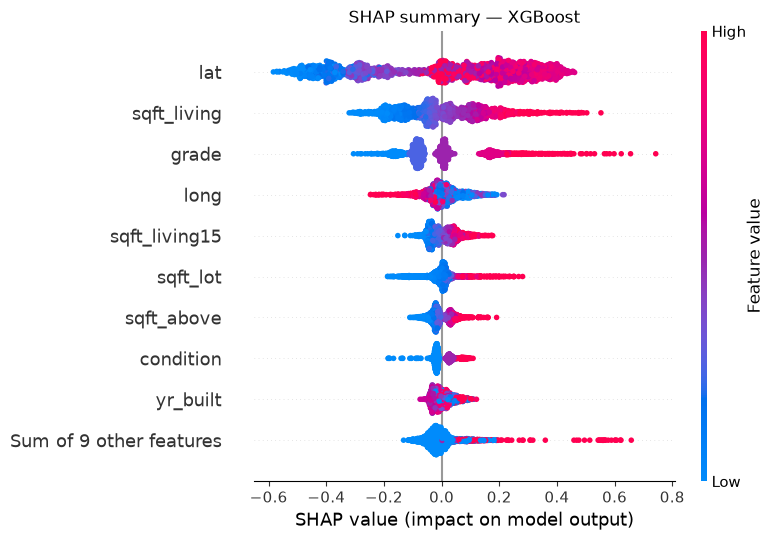

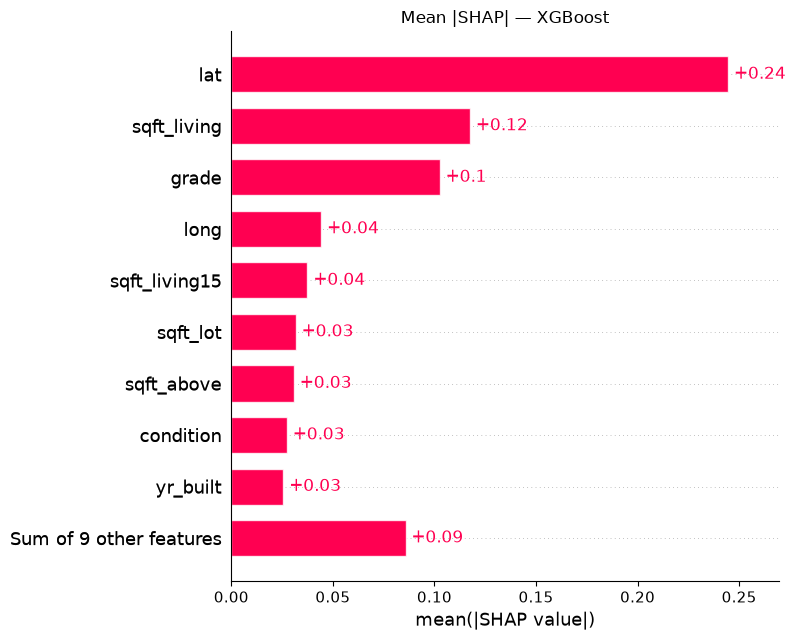

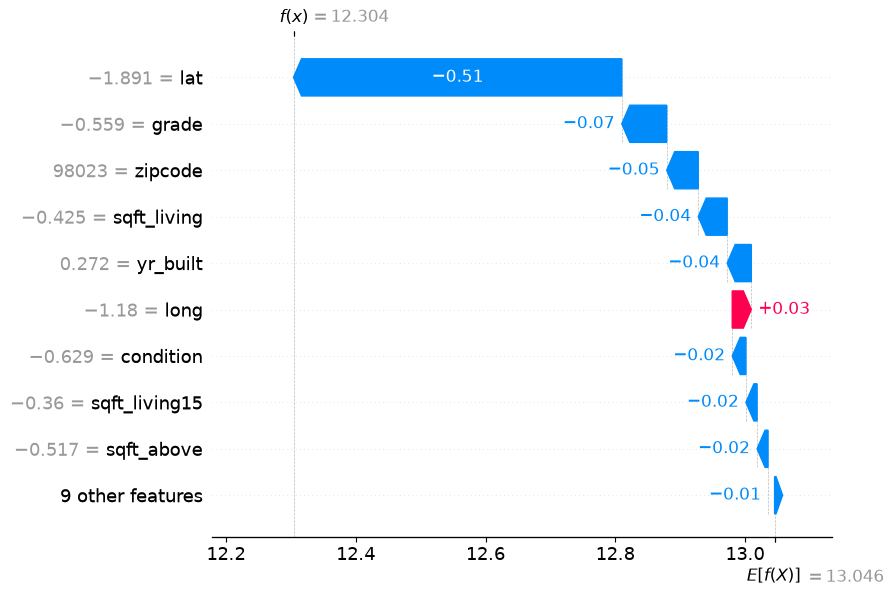

In [13]:
from shap.plots import bar as shap_bar
from shap.plots import beeswarm, waterfall

if best_name in {"XGBoost", "CatBoost"}:
    shap_explainer = shap.TreeExplainer(best_model)
else:
    shap_explainer = shap.Explainer(best_model.predict, X_train)

shap_values = shap_explainer(X_test)
if not isinstance(shap_values, shap.Explanation):
    raise TypeError("Expected a single-output SHAP Explanation")

beeswarm(shap_values, show=False)
plt.title(f"SHAP summary — {best_name}")
plt.tight_layout()
plt.show()

shap_bar(shap_values, show=False)
plt.title(f"Mean |SHAP| — {best_name}")
plt.tight_layout()
plt.show()

waterfall(shap_values[0], show=True)

### LIME

LIME (Local Interpretable Model-agnostic Explanations) fits a sparse linear model around a single house. Use it to check whether a local story matches the global SHAP ranking.

True log_price:      12.4090
Predicted log_price: 12.3040
                             rule    weight
0                    lat <= -0.64 -0.470764
1                  grade <= -0.56 -0.235787
2             waterfront <= -0.09 -0.167960
3              condition <= -0.63 -0.122815
4                   view <= -0.31 -0.060646
5    -0.71 < sqft_living <= -0.18 -0.054006
6                   long <= -0.82  0.050432
7  -0.74 < sqft_living15 <= -0.21 -0.044899
8       -0.24 < sqft_lot <= -0.18 -0.038278
9           yr_renovated <= -0.21 -0.036134


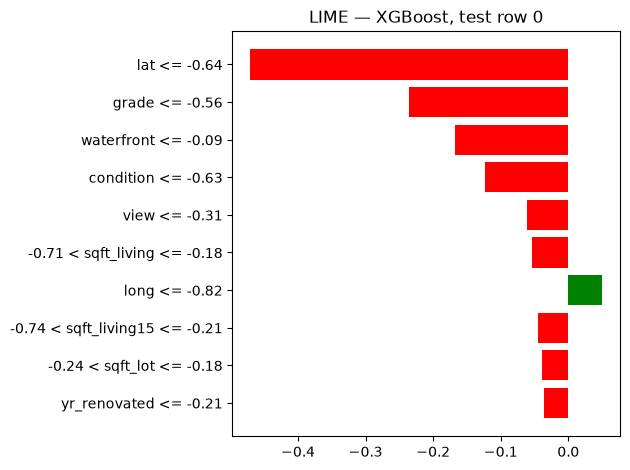

In [14]:
lime_explainer = LimeTabularExplainer(
    training_data=X_train.to_numpy(),
    feature_names=list(X.columns),
    training_labels=y_train.to_numpy(),
    mode="regression",
    random_state=RANDOM_STATE,
)

instance_idx = 0
lime_exp = lime_explainer.explain_instance(
    X_test.iloc[instance_idx].to_numpy(),
    best_model.predict,
    num_features=10,
)

print(f"True log_price:      {y_test.iloc[instance_idx]:.4f}")
print(f"Predicted log_price: {best_model.predict(X_test.iloc[[instance_idx]])[0]:.4f}")
print(pd.DataFrame(lime_exp.as_list(), columns=["rule", "weight"]))

_ = lime_exp.as_pyplot_figure()
plt.title(f"LIME — {best_name}, test row {instance_idx}")
plt.tight_layout()
plt.show()

### What these features reveal about the baselines

On this split, **XGBoost** is the best baseline (test R² ≈ 0.917 vs CatBoost ≈ 0.913 and linear regression ≈ 0.785). SHAP on that model is dominated by a short list of drivers:

- **`lat` is the strongest feature.** North–south location in King County moves `log_price` more than any size or quality field. **`long`** is next among the geographic variables. The trees are mostly learning *where* the house is, then adjusting for the building.
- **`sqft_living` and `grade` are the main property effects.** Living area and King County building grade are the two structural features with large mean |SHAP|. Neighborhood living area (`sqft_living15`) and lot size add a smaller, secondary signal.
- **Layout counts are weak once size is known.** Bedrooms and bathrooms rank far below `sqft_living`. Extra rooms do not raise predicted log-price much after square footage is controlled for — and the linear model’s small negative bedroom coefficient is the same idea in additive form.
- **Linear regression agrees on location and grade, but misses interactions.** Its largest |coefficients| are also `lat` and `grade`, then `yr_built` (negative after controlling for grade and size). It underweights `sqft_living` relative to the trees. That gap is why the linear R² sits ~0.13 below XGBoost: year, grade, and living area do not combine linearly, and a global hyperplane cannot represent “large, high-grade house in a northern ZIP” the way boosted trees can.
- **LIME should usually echo SHAP on a typical house** (`lat`, `sqft_living`, `grade`). When it does not — waterfront, a high `view` score, or an unusual lot — that is a local exception, not a new global ranking. Use LIME to debug individual predictions; use SHAP for what the baseline actually relies on.

For the GNN stage, this says the tabular baselines already treat **geography + living area + grade** as the core of King County prices. A graph model is most useful if it can represent *neighbor structure* beyond `lat`/`long` and `sqft_living15`, not if it rediscovers the same three features.